# TP2 — OLS and Ridge

## Data generation and imports

The features are centred and correlated. There is no intercept. The design is generated once; only the noise is resampled.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=180, bbox_inches="tight")
    plt.show()

def make_design(n=100, p=10, rho=0.9, seed=0):
    rng = np.random.default_rng(seed)
    corr = rho ** np.abs(np.subtract.outer(np.arange(p), np.arange(p)))
    X = rng.multivariate_normal(np.zeros(p), corr, size=n)
    X = X - X.mean(axis=0)
    theta_star = np.zeros(p)
    theta_star[:3] = [2.0, -1.0, 0.5]
    return X, theta_star

def sample_y(X, theta_star, sigma, rng, size=None):
    n = X.shape[0]
    shape = (n,) if size is None else (size, n)
    return X @ theta_star + sigma * rng.standard_normal(shape)

X, theta_star = make_design()
n, p = X.shape
sigma = 1.5
lam = 3.0
rng = np.random.default_rng(1)
y = sample_y(X, theta_star, sigma, rng)
print(f"Design shape: {X.shape}; noise standard deviation: {sigma}")

Design shape: (100, 10); noise standard deviation: 1.5


## Part I — Theoretical comparison

The model is $y=X\theta^\star+\varepsilon$, with $\mathbb E[\varepsilon]=0$ and $\operatorname{Cov}(\varepsilon)=\Sigma$. Write $C=X^TX$, $A_0=C^{-1}X^T$, $A_\lambda=(C+\lambda I)^{-1}X^T$, and $W_\lambda=(C+\lambda I)^{-1}C$.

| Quantity | OLS | Ridge |
|---|---|---|
| Matrix $A$ | $A_0$ | $A_\lambda$ |
| Bias | $0$ | $-\lambda(C+\lambda I)^{-1}\theta^\star$ |
| Covariance, any $\Sigma$ | $A_0\Sigma A_0^T$ | $A_\lambda\Sigma A_\lambda^T$ |
| Covariance, $\Sigma=\sigma^2 I$ | $\sigma^2 C^{-1}$ | $\sigma^2(C+\lambda I)^{-1}C(C+\lambda I)^{-1}$ |
| Quadratic risk | $\sigma^2\operatorname{tr}(C^{-1})$ | $\|\lambda(C+\lambda I)^{-1}\theta^\star\|^2+\operatorname{tr}(\operatorname{Cov}(\hat\theta_\lambda))$ |
| Prediction risk | $\sigma^2p$ | $\lambda^2\|X(C+\lambda I)^{-1}\theta^\star\|^2+\sigma^2\sum_j s_j^4/(s_j^2+\lambda)^2$ |
| BLUE under homoscedasticity? | Yes | No, generally biased |
| What must be known? | $X,y$ | $X,y,\lambda$; oracle tuning additionally depends on unknown parameters |

**Exercise 1 (BLUE):** For a linear unbiased estimator $Ay$, $AX=I_p$. Writing $B=A-A_0$ gives $BX=0$ and $AA^T=BB^T+C^{-1}$. Thus, under $\Sigma=\sigma^2I$, $\operatorname{Cov}(Ay)-\operatorname{Cov}(\hat\theta)=\sigma^2BB^T\succeq0$. This uses centred, uncorrelated, homoscedastic noise, but not Gaussianity. Under heteroscedasticity, the cross terms generally do not vanish.

**Exercise 2 (Ridge):** $\hat\theta_\lambda=W_\lambda\hat\theta$. If $C=\sum_j s_j^2v_jv_j^T$, then $W_\lambda=\sum_j\frac{s_j^2}{s_j^2+\lambda}v_jv_j^T$. Small-eigenvalue directions are shrunk most strongly. Ridge decreases covariance under homoscedasticity but introduces bias; the best theoretical penalty depends on $\theta^\star$ and $\sigma$.

## Part II — Q1. OLS and Ridge

Solve the normal equations without forming an explicit inverse:
$$\hat\theta=(X^TX)^{-1}X^Ty,\qquad \hat\theta_\lambda=(X^TX+\lambda I_p)^{-1}X^Ty.$$

In [2]:
def ols_fit(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

def ridge_fit(X, y, lam):
    if lam < 0:
        raise ValueError("lam must be nonnegative")
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)

C = X.T @ X
I = np.eye(p)
theta_ols = ols_fit(X, y)
theta_ridge = ridge_fit(X, y, lam)
W = np.linalg.solve(C + lam * I, C)
penalties = np.array([0, .01, .1, 1, 3, 10, 100, 1000])
norms = np.array([np.linalg.norm(ridge_fit(X, y, z)) for z in penalties])
check_zero = np.max(np.abs(ridge_fit(X, y, 0) - theta_ols))
check_W = np.max(np.abs(theta_ridge - W @ theta_ols))
check_sklearn = np.max(np.abs(theta_ridge - Ridge(alpha=lam, fit_intercept=False).fit(X, y).coef_))
print("lambda=0 vs OLS, max difference:", check_zero)
print("Ridge vs W @ OLS, max difference:", check_W)
print("Ridge norms (in increasing penalty order):", norms)
print("Norms nonincreasing:", np.all(np.diff(norms) <= 1e-10))
print("NumPy vs sklearn, max difference:", check_sklearn)
assert check_zero < 1e-9 and check_W < 1e-9 and check_sklearn < 1e-9
assert np.all(np.diff(norms) <= 1e-10)

lambda=0 vs OLS, max difference: 0.0
Ridge vs W @ OLS, max difference: 2.1094237467877974e-15
Ridge norms (in increasing penalty order): [2.91249147 2.90699957 2.85882259 2.47411501 1.96953516 1.30438764
 0.60534733 0.22564177]
Norms nonincreasing: True
NumPy vs sklearn, max difference: 1.5543122344752192e-15


## Q2. Design conditioning

The eigenvalues of $X^TX$ determine OLS precision. Under homoscedasticity, the variance along eigenvector $v_j$ is $\sigma^2/s_j^2$, so the smallest eigenvalues correspond to the least precise directions.

Eigenvalues: [  3.56238   4.77019   5.38626   7.81401   8.24055  12.98082  22.90985
  48.9177  145.14214 645.74538]
Condition number: 181.26787664830383
Least precise direction: eigenvector associated with 3.5623817778683833


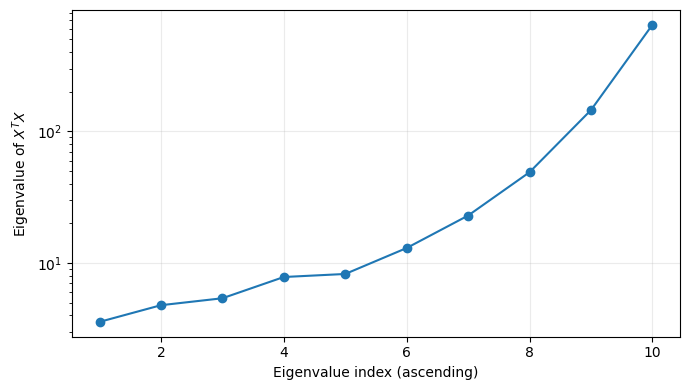

In [3]:
eigenvalues, eigenvectors = np.linalg.eigh(C)
condition_number = np.linalg.cond(C)
print("Eigenvalues:", np.round(eigenvalues, 5))
print("Condition number:", condition_number)
print("Least precise direction: eigenvector associated with", eigenvalues[0])
plt.figure(figsize=(7, 4))
plt.semilogy(np.arange(1, p + 1), eigenvalues, "o-")
plt.xlabel("Eigenvalue index (ascending)")
plt.ylabel("Eigenvalue of $X^TX$")
plt.grid(alpha=.25)
save_figure("eigenvalues.png")

## Q3. Two estimates on one dataset

Compare $\|\hat\theta-\theta^\star\|$ for OLS and Ridge at $\lambda=3$. A single dataset cannot establish which estimator has the smaller expected risk.

OLS estimation error: 1.2026434244630886
Ridge estimation error: 0.7892450427060002
True coefficients: [ 2.  -1.   0.5  0.   0.   0.   0.   0.   0.   0. ]
OLS coefficients: [ 2.14575 -1.51705  0.66917  0.59633 -0.64207  0.45973 -0.18175 -0.07802
 -0.0613   0.32719]
Ridge coefficients: [ 1.61222 -0.78189  0.4935   0.32672 -0.24161  0.30454 -0.15343 -0.03444
 -0.15353  0.34461]


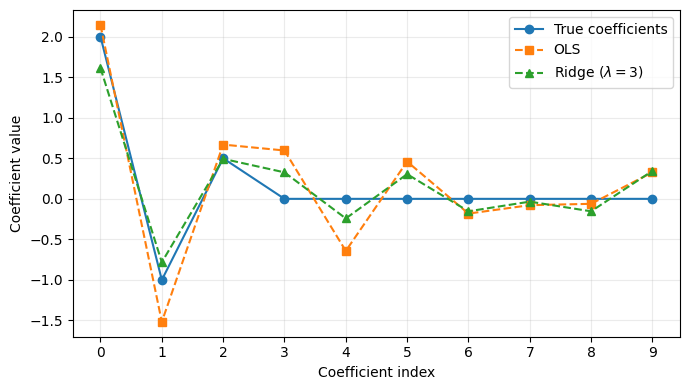

In [4]:
error_ols = np.linalg.norm(theta_ols - theta_star)
error_ridge = np.linalg.norm(theta_ridge - theta_star)
print("OLS estimation error:", error_ols)
print("Ridge estimation error:", error_ridge)
print("True coefficients:", theta_star)
print("OLS coefficients:", np.round(theta_ols, 5))
print("Ridge coefficients:", np.round(theta_ridge, 5))
plt.figure(figsize=(7, 4))
idx = np.arange(p)
plt.plot(idx, theta_star, "o-", label="True coefficients")
plt.plot(idx, theta_ols, "s--", label="OLS")
plt.plot(idx, theta_ridge, "^--", label="Ridge ($\lambda=3$)")
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient value")
plt.xticks(idx)
plt.legend()
plt.grid(alpha=.25)
save_figure("coefficients.png")

## Q4. Theoretical squared bias, variance and risk

For $\tilde\theta=Ay$ and $\Sigma=\sigma^2I_n$:
$$\operatorname{Bias}^2(A)=\|(AX-I_p)\theta^\star\|^2,\qquad V(A)=\sigma^2\operatorname{tr}(AA^T),\qquad R(A)=\operatorname{Bias}^2(A)+V(A).$$

In [5]:
def linear_risk(A, X, theta_star, sigma):
    bias = (A @ X - np.eye(X.shape[1])) @ theta_star
    squared_bias = float(bias @ bias)
    variance = float(sigma**2 * np.sum(A**2))
    return squared_bias, variance

A_ols = np.linalg.solve(C, X.T)
A_ridge = np.linalg.solve(C + lam * I, X.T)
theory_ols = linear_risk(A_ols, X, theta_star, sigma)
theory_ridge = linear_risk(A_ridge, X, theta_star, sigma)
print("OLS (squared bias, variance, risk):", *theory_ols, sum(theory_ols))
print("Ridge (squared bias, variance, risk):", *theory_ridge, sum(theory_ridge))
print("OLS variance formula sigma² tr(C^-1):", sigma**2 * np.trace(np.linalg.solve(C, I)))

OLS (squared bias, variance, risk): 2.4133804417762952e-28 2.4185196363506214 2.4185196363506214
Ridge (squared bias, variance, risk): 0.5228715083294828 1.0836129730927793 1.606484481422262
OLS variance formula sigma² tr(C^-1): 2.41851963635063


## Q5. Monte Carlo verification

With $M=2000$ independent response vectors and the same $X$, compute the empirical squared bias $\|\bar\theta-\theta^\star\|^2$, variance $M^{-1}\sum_m\|\hat\theta^{(m)}-\bar\theta\|^2$, and risk $M^{-1}\sum_m\|\hat\theta^{(m)}-\theta^\star\|^2$.

In [6]:
def empirical_summary(estimates, theta_star):
    average = estimates.mean(axis=0)
    squared_bias = np.sum((average - theta_star)**2)
    variance = np.mean(np.sum((estimates - average)**2, axis=1))
    risk = np.mean(np.sum((estimates - theta_star)**2, axis=1))
    return float(squared_bias), float(variance), float(risk)

M = 2000
rng = np.random.default_rng(2)
Y = sample_y(X, theta_star, sigma, rng, size=M)
empirical_ols = empirical_summary(Y @ A_ols.T, theta_star)
empirical_ridge = empirical_summary(Y @ A_ridge.T, theta_star)
for name, theory, empirical in [("OLS", theory_ols, empirical_ols), ("Ridge", theory_ridge, empirical_ridge)]:
    print(name)
    print("  theoretical bias², variance, risk:", *np.round([*theory, sum(theory)], 5))
    print("  empirical bias², variance, risk:  ", *np.round(empirical, 5))

OLS
  theoretical bias², variance, risk: 0.0 2.41852 2.41852
  empirical bias², variance, risk:   0.00219 2.37973 2.38192
Ridge
  theoretical bias², variance, risk: 0.52287 1.08361 1.60648
  empirical bias², variance, risk:   0.52072 1.0674 1.58812


## Q6. Choice of the penalty $\lambda$

Evaluate theoretical bias, variance and risk on a logarithmic grid from $10^{-2}$ to $10^3$. The minimizer on this grid is an *oracle* choice because it uses the unknown true parameter and noise level.

Best lambda on the grid: 3.1622776601683795
Minimum theoretical Ridge risk: 1.6066986875374183
OLS theoretical risk: 2.4185196363506214
Grid lambda range beating OLS: (np.float64(0.01), np.float64(14.125375446227554))


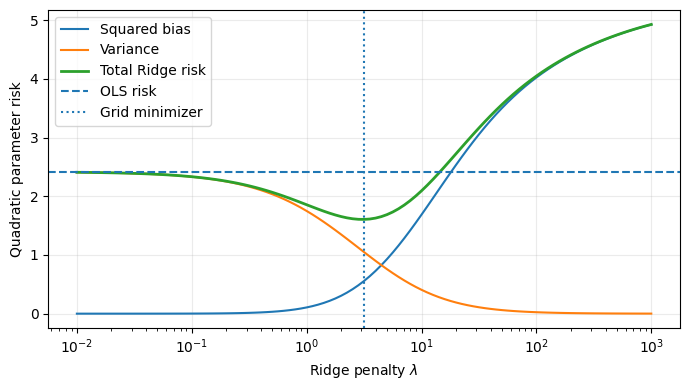

Monte Carlo spot checks (lambda, theoretical risk, empirical risk):
  0.1: 2.33432, 2.29958
  3: 1.60648, 1.58812
  3.162: 1.60670, 1.58851
  100: 4.05030, 4.04476


In [7]:
lams = np.logspace(-2, 3, 101)
curves = np.array([linear_risk(np.linalg.solve(C + z * I, X.T), X, theta_star, sigma) for z in lams])
risks = curves.sum(axis=1)
minimum_index = np.argmin(risks)
lam_star = float(lams[minimum_index])
min_risk = float(risks[minimum_index])
beats_ols = lams[risks < sum(theory_ols)]
print("Best lambda on the grid:", lam_star)
print("Minimum theoretical Ridge risk:", min_risk)
print("OLS theoretical risk:", sum(theory_ols))
print("Grid lambda range beating OLS:", (beats_ols[0], beats_ols[-1]) if len(beats_ols) else "None")
plt.figure(figsize=(7, 4))
plt.semilogx(lams, curves[:, 0], label="Squared bias")
plt.semilogx(lams, curves[:, 1], label="Variance")
plt.semilogx(lams, risks, label="Total Ridge risk", linewidth=2)
plt.axhline(sum(theory_ols), linestyle="--", label="OLS risk")
plt.axvline(lam_star, linestyle=":", label="Grid minimizer")
plt.xlabel("Ridge penalty $\lambda$")
plt.ylabel("Quadratic parameter risk")
plt.legend()
plt.grid(alpha=.25)
save_figure("risk_curve.png")
print("Monte Carlo spot checks (lambda, theoretical risk, empirical risk):")
for z in [0.1, 3.0, lam_star, 100.0]:
    A_z = np.linalg.solve(C + z * I, X.T)
    theoretical = sum(linear_risk(A_z, X, theta_star, sigma))
    empirical = empirical_summary(Y @ A_z.T, theta_star)[2]
    print(f"  {z:.4g}: {theoretical:.5f}, {empirical:.5f}")

## Q7. Comparison on new datasets

Use a fresh sample of $M$ response vectors and compare the squared parameter errors of OLS and Ridge with the oracle penalty from Q6. In practice, this oracle penalty is unavailable because $\theta^\star$ and $\sigma$ are unknown; cross-validation provides a data-driven alternative.

OLS: mean = 2.3812440623413065 ; median = 2.1039068829110583
Ridge: mean = 1.6116939364729843 ; median = 1.4519447172766016


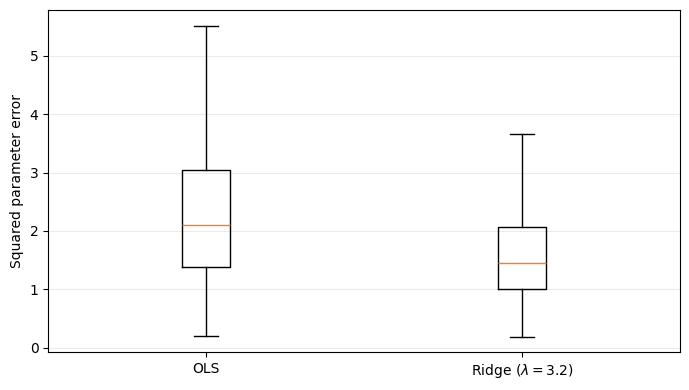

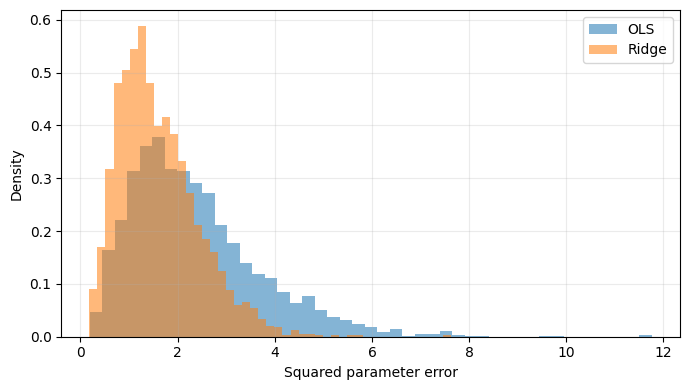

In [8]:
rng = np.random.default_rng(4)
Y_new = sample_y(X, theta_star, sigma, rng, size=M)
A_star = np.linalg.solve(C + lam_star * I, X.T)
squared_ols = np.sum((Y_new @ A_ols.T - theta_star)**2, axis=1)
squared_ridge = np.sum((Y_new @ A_star.T - theta_star)**2, axis=1)
print("OLS: mean =", squared_ols.mean(), "; median =", np.median(squared_ols))
print("Ridge: mean =", squared_ridge.mean(), "; median =", np.median(squared_ridge))
plt.figure(figsize=(7, 4))
plt.boxplot([squared_ols, squared_ridge], tick_labels=["OLS", f"Ridge ($\lambda={lam_star:.2g}$)"], showfliers=False)
plt.ylabel("Squared parameter error")
plt.grid(axis="y", alpha=.25)
save_figure("error_boxplot.png")
plt.figure(figsize=(7, 4))
plt.hist(squared_ols, bins=45, alpha=.55, label="OLS", density=True)
plt.hist(squared_ridge, bins=45, alpha=.55, label="Ridge", density=True)
plt.xlabel("Squared parameter error")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=.25)
save_figure("error_histogram.png")

## Conclusion

OLS is unbiased and BLUE under the homoscedastic fixed-design model, but correlation among features can make its variance large. Ridge introduces shrinkage and bias while reducing variance. The appropriate penalty balances both effects. The numerical experiments distinguish single-sample estimation error from expected quadratic risk.